# Лабораторная работа №8 (В26)
## Введение
**Название:** бинарная классификация с использованием нейросети

**Цели:** изучить архитектуру и принцип работы нейронных сетей на примере решения задачи бинарной классификации

**Описание показателей:**
- age - возраст
- job - тип работы
- marital - семейное положение
- education - образование
- default - просрочен ли кредит
- balance - среднегодовой баланс в евро
- housing - есть ли ссуда на жильё
- loan - есть ли ссуда на личные нужды
- contact - тип связи с контактом
- day - последний день контакта в месяце
- month - месяц последнего контакта в году
- duration - продолжительность последнего контакта в секундах
- campaign - количество контактов, осуществлённых в ходе этой компании и для данного клиента
- pdays - количество дней с момента последнего контакта с клиентом в рамках предыдущей компании
- previous - количество контактов, осуществлённых до этой компании и для данного клиента
- poutcome - результат предыдущей маркетинговой компании

## 1. Подготовительный этап
### 1.1 Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
#!pip install tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

I0000 00:00:1792296315.111019   20974 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792296321.053011   20974 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### 1.2 Загрузка датасета

In [2]:
# используем указание разделителя delimiter
df = pd.read_csv('bank.csv', delimiter = ';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


### 1.3 Извлечение последней строки датафрейма

In [4]:
row_to_rm = df.iloc[4520]
df = df.drop(4520)
print("Удалённая строка:")
print(row_to_rm)
print(f"Тип: {type(row_to_rm)}")

Удалённая строка:
age                    44
job          entrepreneur
marital            single
education        tertiary
default                no
balance              1136
housing               yes
loan                  yes
contact          cellular
day                     3
month                 apr
duration              345
campaign                2
pdays                 249
previous                7
poutcome            other
y                      no
Name: 4520, dtype: object
Тип: <class 'pandas.core.series.Series'>


## 2. Преобразование данных
### 2.1 Пропуски, кодирование, деление
Пропуски отстствуют, разделим датасет на целевую перемнную и признаки, закодируем категориальные переменные и разделим на обучающую и тестовую выборки

In [5]:
y = df['y']
X = df.drop('y', axis=1)
X = pd.get_dummies(X, drop_first=True)
y = pd.get_dummies(y, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

### 2.2 Масштабирование признаков
Нейросети лучше работают на одном масштабе

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Создание модели
### 3.1 Построение модели с Keras API
Создадим простую полносвязную нейронную сеть

In [7]:
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

E0000 00:00:1792296325.364000   20974 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



### 3.2 Компиляция модели

In [8]:
model. compile(optimizer='adam', loss="binary_crossentropy",
               metrics=['accuracy', keras.metrics.Precision(), 
                        keras.metrics.Recall()]
)

### 3.3 Обучение модели с валидацией
Добавим раннюю остановку и callback для сохранения лучших весов

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=10,
    restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2, epochs=100,
    batch_size=32, verbose=1,
    callbacks=[early_stop])

Epoch 1/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8409 - loss: 0.4350 - precision: 0.1618 - recall: 0.0816 - val_accuracy: 0.8867 - val_loss: 0.2966 - val_precision: 0.5000 - val_recall: 0.0122
Epoch 2/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8842 - loss: 0.3123 - precision: 0.5625 - recall: 0.1050 - val_accuracy: 0.8964 - val_loss: 0.2517 - val_precision: 0.8889 - val_recall: 0.0976
Epoch 3/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8890 - loss: 0.2849 - precision: 0.5902 - recall: 0.2099 - val_accuracy: 0.9075 - val_loss: 0.2410 - val_precision: 0.8000 - val_recall: 0.2439
Epoch 4/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8973 - loss: 0.2499 - precision: 0.6825 - recall: 0.2507 - val_accuracy: 0.9144 - val_loss: 0.2329 - val_precision: 0.7632 - val_recall: 0.3537
Epoch 5/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9018 - loss: 0.2375 - precision: 0.6746 - recall: 0.3324 - val_accuracy: 0.9157 - val_loss: 0.233

## 4. Анализ получившейся модели
### 4.1 Оценка на тестовых данных

In [10]:
test_loss, test_acc, test_prec, test_rec = model.evaluate(X_test_scaled, y_test)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Precision: {test_prec*100:.2f}%")
print(f"Test Recall: {test_rec*100:.2f}%")

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8894 - loss: 0.2449 - precision: 0.4600 - recall: 0.2396
Test Accuracy: 88.94%
Test Precision: 46.00%
Test Recall: 23.96%


### 4.2 Визуализация процесса обучения

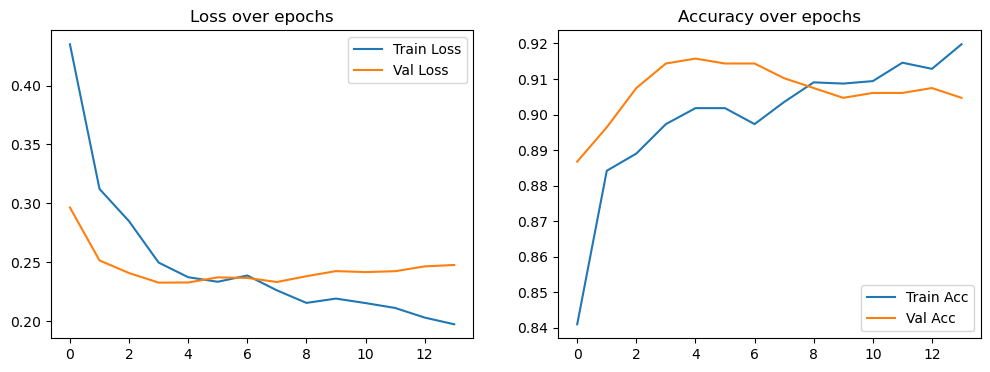

In [11]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss over epochs")
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

**[ДО РЕСТАРТА]** Как можно заметить по графикам, к сожалению, пошло переобучение: с увеличением эпох модель становилась хуже на тестовых и лучше на тренировочных данных, что не хорошо. При этом также стоит отметить, что несмотря на ухудшения, значение всё равно в очень хорошем диапозоне - 90% acc на тестовой выборке держится стабильно

**[ПОСЛЕ РЕСТАРТА]** графики иллюстрируют, что модель улучшается в самом начале - потери становятся меньше, а аккуратность выше. Однако момент начала переобучения также заметен на обоих графиках (в рафоне 4-8 эпох)

### 4.3 Предсказание для нового клиента

In [12]:
rrm_y = row_to_rm['y']
rrm_x = row_to_rm.drop('y')
rrm_x = pd.get_dummies(rrm_x, drop_first=True)

rrm_x.columns = rrm_x.columns.astype(str)
rrm_x = rrm_x.reindex(columns=X_train.columns, fill_value=0)

new_scaled = scaler.transform(rrm_x)
prob = model.predict(new_scaled)[0][0]
print(f"Вероятность выдачи кредита: {prob*100:.2f}%")
print("Верный ответ:", rrm_y)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
Вероятность выдачи кредита: 7.00%
Верный ответ: no


Ответ моделью был дан верный! Замечу, что до рестарта модель дала лишь 4%, а после уже 7%. Это превышение в 2 раза, хотя на суть ответа влияет не сильно - в числовой оценке добавление 3%, когда для победы надо одержать 50%+, это лишь погрешность в 6% (6/100), что неприятно, но не критично. 

Лабораторная работа 8 выполнена.